# 04 · Clusterização dos países

Agrupa os países pela **forma da trajetória** de indicadores demográficos entre 1950 e 2023, com DTW (*Dynamic Time Warping*) e k-means.

O notebook faz quatro coisas:

1. **Grade de parâmetros:** testa conjuntos de indicadores, filtros de população e número de grupos, medindo silhueta e estabilidade entre sementes.
2. **Modelo final:** ajusta o modelo com a configuração escolhida na grade e nomeia os grupos.
3. **Mapa dos grupos:** mostra o resultado no mapa-múndi, e depois a clusterização transversal por época.
4. **Sankey:** mostra como os países migram entre grupos de 1950 a 2100.

**Saída:** `data/processed/clusters_dtw.csv`, lido pelo dashboard.

In [10]:
import sys
from pathlib import Path

# Permite importar src/ a partir da pasta notebooks/
if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import cdist_dtw
from vega_datasets import data

from src.dados import carregar_medium, paises
from src.preparo import matriz_series, padronizar

alt.data_transformers.disable_max_rows()

RAIZ = Path.cwd().parent
medium = carregar_medium()
paises_medium = paises(medium)
MALHA = alt.topo_feature(data.world_110m.url, "countries")

PERIODO = (1950, 2023)
CORES = ["#2a78d6", "#1baf7a", "#eda100", "#eb6834", "#e87ba4", "#6250d6", "#008300"]

## 1. Parâmetros da grade

- **Conjuntos de indicadores:** o conjunto A é o de referência. O conjunto B acrescenta a migração líquida, que é mais instável entre países.
- **População mínima:** descarta países pequenos (séries ruidosas). O valor é em milhares; 1000 equivale a 1 milhão de habitantes.
- **Número de grupos (K)** e **sementes:** a estabilidade é medida pelo ARI entre duas sementes.

In [11]:
CONJUNTOS = {
    "A: TFR, LEx, IMR, idade": ["TFR", "LEx", "IMR", "MedianAgePop"],
    "B: A + migração": ["TFR", "LEx", "IMR", "MedianAgePop", "NetMigrations"],
}
POP_MINIMAS = [None, 1000]
KS = [3, 4, 5]
SEMENTES = [0, 1]

## 2. Preparação dos dados

Para cada conjunto e filtro, mantemos só os países com série completa em 1950–2023 e padronizamos os indicadores com média e desvio de todo o conjunto.

In [12]:
def preparar(features, pop_minima_mil=None, periodo=PERIODO):
    """Matriz (países, anos, indicadores) pronta para o DTW."""
    base = paises_medium[paises_medium["Time"].between(*periodo)]
    if pop_minima_mil is not None:
        media_pop = base.groupby("LocID")["TPopulation1July"].mean()
        base = base[base["LocID"].isin(media_pop[media_pop >= pop_minima_mil].index)]

    colunas = ["LocID", "Location", "Time"] + sorted(set(features) | {"TFR"})
    base = base[colunas].dropna()
    completos = base.groupby("LocID")["Time"].transform("size") == (periodo[1] - periodo[0] + 1)
    base = base[completos]

    z = padronizar(base, features)
    X, ids, nomes = matriz_series(z, features)
    return X, ids, nomes

X_teste, ids_teste, _ = preparar(CONJUNTOS["A: TFR, LEx, IMR, idade"])
print("Conjunto A, sem filtro: X =", X_teste.shape)

Conjunto A, sem filtro: X = (237, 74, 4)


## 3. Grade de parâmetros

Para cada combinação, ajustamos o modelo com duas sementes. Medimos:
- **silhueta** com a distância DTW (quanto maior, melhor separados os grupos);
- **ARI entre sementes** (quanto maior, mais estável o agrupamento).

A tabela resume a grade. É o principal critério para escolher a configuração final.

In [13]:
linhas = []
distancias = {}
for nome_conjunto, features in CONJUNTOS.items():
    for pop_minima in POP_MINIMAS:
        X, ids, _ = preparar(features, pop_minima)
        D = cdist_dtw(X)
        for k in KS:
            rotulos = {}
            for semente in SEMENTES:
                modelo = TimeSeriesKMeans(n_clusters=k, metric="dtw", random_state=semente, max_iter=20).fit(X)
                rotulos[semente] = modelo.labels_
            linhas.append({
                "conjunto": nome_conjunto,
                "pop. mínima (mil)": "sem filtro" if pop_minima is None else pop_minima,
                "K": k,
                "países": len(ids),
                "silhueta": silhouette_score(D, rotulos[SEMENTES[0]], metric="precomputed"),
                "ARI entre sementes": adjusted_rand_score(rotulos[SEMENTES[0]], rotulos[SEMENTES[1]]),
            })

grade = pd.DataFrame(linhas).round(3)
grade

,conjunto,pop. mínima (mil),K,países,silhueta,ARI entre sementes
0,"A: TFR, LEx, IMR, idade",sem filtro,3,237,0.361,0.553
1,"A: TFR, LEx, IMR, idade",sem filtro,4,237,0.298,0.646
2,"A: TFR, LEx, IMR, idade",sem filtro,5,237,0.271,0.611
3,"A: TFR, LEx, IMR, idade",1000,3,154,0.407,0.583
4,"A: TFR, LEx, IMR, idade",1000,4,154,0.339,0.504
5,"A: TFR, LEx, IMR, idade",1000,5,154,0.305,0.579
6,B: A + migração,sem filtro,3,237,0.277,0.267
7,B: A + migração,sem filtro,4,237,0.193,0.384
8,B: A + migração,sem filtro,5,237,0.194,0.380
9,B: A + migração,1000,3,154,0.288,0.536


## 4. Configuração final

**Decisão, com base na grade:**
- **Conjunto de indicadores:** o conjunto A. Acrescentar a migração (B) reduz a silhueta e a estabilidade em todas as combinações testadas (ARI entre 0,27 e 0,61, contra 0,50 a 0,65 do A).
- **Filtro de população:** sem filtro. O filtro de 1 milhão melhora a silhueta, mas deixa 83 países de fora. Mantemos todos os 237, porque a análise é sobre o mundo.
- **K = 4:** a silhueta cai de 0,36 (K=3) para 0,30 (K=4), mas K=4 tem o maior ARI entre sementes (0,65) e quatro fases interpretáveis, que é o que a apresentação precisa. Com K=3 a silhueta é melhor, mas os grupos misturam transições diferentes.

A semente final é 0. Para o resultado definitivo, convém conferir o consenso entre sementes (ver Limitações).

In [14]:
CONJUNTO_FINAL = "A: TFR, LEx, IMR, idade"
POP_FINAL = None
K_FINAL = 4
SEMENTE_FINAL = 0

## 5. Ajuste do modelo final e nomes dos grupos

Os grupos são numerados pela fecundidade média de 1950–2023 (do menor para o maior) e recebem nomes que descrevem a fase da transição.

In [15]:
def nomes_grupos(k):
    if k == 3:
        return ["Baixa fecundidade", "Transição", "Alta fecundidade"]
    if k == 4:
        return ["Baixa fecundidade", "Transição avançada", "Transição inicial", "Alta fecundidade"]
    if k == 5:
        return ["Baixa fecundidade", "Transição avançada", "Transição intermediária", "Transição inicial", "Alta fecundidade"]
    return [f"Grupo {i + 1}" for i in range(k)]

X, ids, nomes = preparar(CONJUNTOS[CONJUNTO_FINAL], POP_FINAL)
modelo = TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=SEMENTE_FINAL, max_iter=20).fit(X)

tfr_medio = paises_medium[paises_medium["Time"].between(*PERIODO)].groupby("LocID")["TFR"].mean()
resultado = pd.DataFrame({"LocID": ids, "Location": nomes, "grupo_bruto": modelo.labels_})
resultado["TFR_medio"] = resultado["LocID"].map(tfr_medio)
ordem = resultado.groupby("grupo_bruto")["TFR_medio"].mean().sort_values().index.tolist()
ranking = {g: i for i, g in enumerate(ordem)}
resultado["grupo"] = resultado["grupo_bruto"].map(ranking)
resultado["nome"] = resultado["grupo"].map(lambda g: nomes_grupos(K_FINAL)[g])

print(resultado.groupby("nome").size().rename("países").to_string())

nome
Alta fecundidade      64
Baixa fecundidade     58
Transição avançada    79
Transição inicial     36


In [16]:
for g in range(K_FINAL):
    membros = resultado.loc[resultado["grupo"] == g, "Location"].tolist()
    print(f"{nomes_grupos(K_FINAL)[g]} ({len(membros)} países):")
    print("  " + ", ".join(membros))
    print()

Baixa fecundidade (58 países):
  Andorra, Argentina, Australia, Austria, Belgium, Bermuda, Bulgaria, Belarus, Canada, Croatia, Czechia, Denmark, Estonia, Faroe Islands, Falkland Islands (Malvinas), Finland, France, Georgia, Germany, Gibraltar, Greece, Holy See, Hungary, Iceland, Ireland, Italy, Japan, Latvia, Liechtenstein, Lithuania, Luxembourg, Malta, Monaco, Republic of Moldova, Netherlands, New Zealand, Norway, Poland, Portugal, Romania, Russian Federation, Saint Barthélemy, Saint Pierre and Miquelon, San Marino, Serbia, Slovakia, Slovenia, Spain, Sweden, Switzerland, Ukraine, North Macedonia, United Kingdom, Guernsey, Jersey, Isle of Man, United States of America, Uruguay

Transição avançada (79 países):
  Albania, American Samoa, Antigua and Barbuda, Bahamas, Bahrain, Armenia, Barbados, Bosnia and Herzegovina, Brazil, Belize, British Virgin Islands, Brunei Darussalam, Cayman Islands, Sri Lanka, Chile, China, China, Taiwan Province of China, Colombia, Cook Islands, Costa Rica, Cub

## 6. Trajetórias típicas de cada grupo

As linhas finas são os países e a linha grossa é o centroide do grupo. Os valores estão padronizados (z-score), então o eixo é relativo.

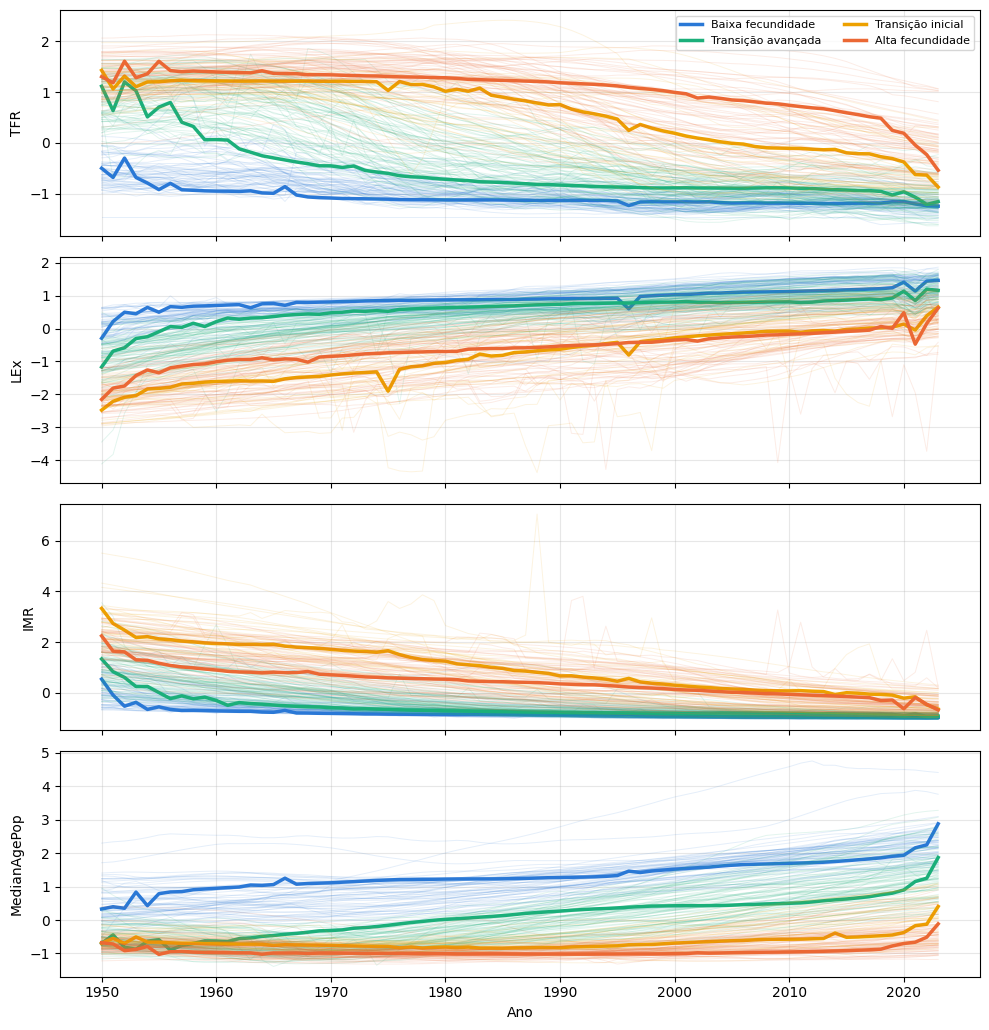

In [17]:
INDICADORES_PLOT = CONJUNTOS[CONJUNTO_FINAL]
anos = np.arange(PERIODO[0], PERIODO[1] + 1)
inverso = {v: k for k, v in ranking.items()}

fig, eixos = plt.subplots(len(INDICADORES_PLOT), 1, figsize=(10, 2.6 * len(INDICADORES_PLOT)), sharex=True)
for i, ind in enumerate(INDICADORES_PLOT):
    ax = eixos[i]
    for g in range(K_FINAL):
        bruto = inverso[g]
        mascara = modelo.labels_ == bruto
        for serie in X[mascara]:
            ax.plot(anos, serie[:, i], color=CORES[g], alpha=0.12, linewidth=0.7)
        ax.plot(anos, modelo.cluster_centers_[bruto][:, i], color=CORES[g], linewidth=2.5,
                label=nomes_grupos(K_FINAL)[g])
    ax.set_ylabel(ind)
    ax.grid(alpha=0.3)
eixos[0].legend(loc="upper right", ncol=2, fontsize=8)
eixos[-1].set_xlabel("Ano")
fig.tight_layout()
plt.show()

## 7. Mapa dos grupos

Cada país aparece com a cor do seu grupo. Países em cinza não entram na clusterização: não têm série completa, são pequenos demais ou não estão na malha de 110 m.

In [18]:
dados_mapa = resultado[["LocID", "Location", "nome"]]
escala_grupo = alt.Scale(domain=nomes_grupos(K_FINAL), range=CORES[:K_FINAL])

mapa_grupos = (
    alt.Chart(MALHA)
    .mark_geoshape(stroke="white", strokeWidth=0.3)
    .transform_filter("datum.id != 10")
    .transform_lookup(lookup="id", from_=alt.LookupData(dados_mapa, "LocID", ["nome", "Location"]))
    .encode(
        color=alt.condition(
            "isValid(datum.nome)",
            alt.Color("nome:N", scale=escala_grupo, legend=alt.Legend(title="Grupo")),
            alt.value("#d9d9d9"),
        ),
        tooltip=[alt.Tooltip("Location:N", title="País"), alt.Tooltip("nome:N", title="Grupo")],
    )
    .project(type="equalEarth")
    .properties(width=680, height=340, title="Grupos de fecundidade (DTW, 1950–2023)")
)
mapa_grupos

alt.Chart(...)

## 8. Grupos por época no mapa

A clusterização por DTW usa a trajetória inteira, então não dá para ver o grupo de um país em um ano específico. Para isso, agrupamos cada época separadamente (k-means sobre os indicadores daquele ano). Os grupos são os mesmos da seção 5, nomeados pela fecundidade média de cada época.

In [19]:
EPOCAS = [1950, 1970, 1990, 2010, 2030, 2050, 2100]
INDICADORES_EPOCA = CONJUNTOS[CONJUNTO_FINAL]

def grupos_por_epoca(features, k, epocas=EPOCAS):
    base = paises_medium[paises_medium["Time"].between(1950, 2100)].dropna(subset=features + ["TFR"])
    z = padronizar(base, features)
    saidas = []
    for epoca in epocas:
        recorte = z[z["Time"] == epoca]
        brutos = base[base["Time"] == epoca]
        modelo_epoca = KMeans(n_clusters=k, n_init=10, random_state=42).fit(recorte[features])
        rot = pd.Series(modelo_epoca.labels_, index=recorte.index).reindex(brutos.index)
        media_tfr = brutos.assign(g=rot.values).groupby("g")["TFR"].mean().sort_values()
        rank = {g: i for i, g in enumerate(media_tfr.index)}
        saidas.append(pd.DataFrame({
            "LocID": brutos["LocID"].values,
            "Location": brutos["Location"].values,
            "epoca": epoca,
            "grupo": [rank[g] for g in rot.values],
        }))
    return pd.concat(saidas, ignore_index=True)

grupos_epoca = grupos_por_epoca(INDICADORES_EPOCA, K_FINAL)
grupos_epoca["nome"] = grupos_epoca["grupo"].map(lambda g: nomes_grupos(K_FINAL)[g])
print(grupos_epoca.groupby(["epoca", "nome"]).size().unstack(fill_value=0)[nomes_grupos(K_FINAL)].to_string())

nome   Baixa fecundidade  Transição avançada  Transição inicial  Alta fecundidade
epoca                                                                            
1950                  46                  65                 50                76
1970                  70                  61                 57                49
1990                  79                  62                 50                46
2010                  85                  71                 41                40
2030                  90                  68                 48                31
2050                  96                  63                 49                29
2100                  41                 103                 56                37


In [20]:
def mapa_epoca(epoca, legenda=False):
    d = grupos_epoca[grupos_epoca["epoca"] == epoca][["LocID", "Location", "nome"]]
    return (
        alt.Chart(MALHA)
        .mark_geoshape(stroke="white", strokeWidth=0.2)
        .transform_filter("datum.id != 10")
        .transform_lookup(lookup="id", from_=alt.LookupData(d, "LocID", ["nome", "Location"]))
        .encode(
            color=alt.condition(
                "isValid(datum.nome)",
                alt.Color("nome:N", scale=escala_grupo, legend=None),
                alt.value("#d9d9d9"),
            ),
            tooltip=[alt.Tooltip("Location:N", title="País"), alt.Tooltip("nome:N", title="Grupo")],
        )
        .project(type="equalEarth")
        .properties(width=400, height=200, title=str(epoca))
    )

legenda_grupos = (
    alt.Chart(pd.DataFrame({"nome": nomes_grupos(K_FINAL)}))
    .mark_square(size=220, filled=True)
    .encode(
        y=alt.Y("nome:N", sort=nomes_grupos(K_FINAL), axis=alt.Axis(title=None, orient="right")),
        color=alt.Color("nome:N", scale=escala_grupo, legend=None),
    )
    .properties(width=40, height=140, title="Grupo")
)

alt.hconcat(
    alt.vconcat(
        alt.hconcat(mapa_epoca(1950), mapa_epoca(1990)),
        alt.hconcat(mapa_epoca(2030), mapa_epoca(2100)),
    ),
    legenda_grupos,
)

alt.HConcatChart(...)

## 9. Sankey: migração entre grupos por época

Cada coluna é uma época; cada bloco é um grupo, com o número de países no tamanho do bloco. Os fluxos ligam os países que estavam em um grupo numa época e estão em outro na época seguinte. A cor do fluxo é a do grupo de origem.

In [21]:
def hex_para_rgba(cor, alfa):
    r, g, b = (int(cor[i:i + 2], 16) for i in (1, 3, 5))
    return f"rgba({r},{g},{b},{alfa})"

def sankey_epocas(grupos, k):
    nomes = nomes_grupos(k)
    epocas = sorted(grupos["epoca"].unique())
    total = grupos["LocID"].nunique()
    contagem = grupos.groupby(["epoca", "grupo"]).size()

    # Posições fixas: uma coluna por época; blocos empilhados do topo para a base
    margem_topo, altura_util, espaco = 0.90, 0.80, 0.02
    x_pos, y_pos, rotulos, cores_no, no_idx = [], [], [], [], {}
    for i, epoca in enumerate(epocas):
        x = 0.02 + i * (0.96 / (len(epocas) - 1))
        y = margem_topo
        for g in range(k):
            n = int(contagem.get((epoca, g), 0))
            if n == 0:
                continue
            altura = altura_util * n / total
            no_idx[(epoca, g)] = len(rotulos)
            x_pos.append(x)
            y_pos.append(min(0.99, max(0.01, y - altura / 2)))
            rotulos.append(f"{n}")
            cores_no.append(CORES[g])
            y -= altura + espaco

    origem, destino, valor, cor_fluxo, texto = [], [], [], [], []
    for e1, e2 in zip(epocas[:-1], epocas[1:]):
        a = grupos[grupos["epoca"] == e1].set_index("LocID")["grupo"]
        b = grupos[grupos["epoca"] == e2].set_index("LocID")["grupo"]
        juntos = pd.concat([a.rename("de"), b.rename("para")], axis=1).dropna()
        for (de, para), n in juntos.groupby(["de", "para"]).size().items():
            origem.append(no_idx[(e1, int(de))])
            destino.append(no_idx[(e2, int(para))])
            valor.append(int(n))
            cor_fluxo.append(hex_para_rgba(CORES[int(de)], 0.45))
            texto.append(f"{n} países: {nomes[int(de)]} em {e1} → {nomes[int(para)]} em {e2}")

    fig = go.Figure(go.Sankey(
        arrangement="fixed",
        node=dict(label=rotulos, x=x_pos, y=y_pos, color=cores_no, pad=4, thickness=18,
                  line=dict(color="white", width=0.5)),
        link=dict(source=origem, target=destino, value=valor, color=cor_fluxo,
                  customdata=texto, hovertemplate="%{customdata}<extra></extra>"),
    ))

    anotacoes = [
        dict(x=0.02 + i * (0.96 / (len(epocas) - 1)), y=1.06, xref="paper", yref="paper",
             text=f"<b>{epoca}</b>", showarrow=False, font=dict(size=13))
        for i, epoca in enumerate(epocas)
    ]
    legenda = "   ".join(f"<span style='color:{CORES[g]}'>■</span> {nomes[g]}" for g in range(k))
    anotacoes.append(dict(x=0.5, y=-0.04, xref="paper", yref="paper", text=legenda,
                          showarrow=False, font=dict(size=12)))

    fig.update_layout(
        title=dict(text="Países por grupo em cada época (número de países em cada bloco)", x=0.01),
        height=560, margin=dict(l=20, r=20, t=90, b=80),
        annotations=anotacoes, font=dict(family="Arial", size=12),
        paper_bgcolor="white", plot_bgcolor="white",
    )
    return fig

fig_sankey = sankey_epocas(grupos_epoca, K_FINAL)
fig_sankey

## 10. Salvar resultados

- `data/processed/clusters_dtw.csv`: grupo de cada país, com o nome (usado pelo dashboard).
- `data/processed/grupos_por_epoca.csv`: grupo de cada país em cada época.
- `figures/sankey_grupos_por_epoca.html`: Sankey interativo, para a apresentação.

In [22]:
SAIDA_CLUSTERS = RAIZ / "data" / "processed" / "clusters_dtw.csv"
SAIDA_EPOCAS = RAIZ / "data" / "processed" / "grupos_por_epoca.csv"
SAIDA_SANKEY = RAIZ / "figures" / "sankey_grupos_por_epoca.html"

SAIDA_CLUSTERS.parent.mkdir(parents=True, exist_ok=True)
SAIDA_SANKEY.parent.mkdir(parents=True, exist_ok=True)

resultado[["LocID", "Location", "grupo", "nome"]].to_csv(SAIDA_CLUSTERS, index=False)
grupos_epoca[["LocID", "Location", "epoca", "grupo", "nome"]].to_csv(SAIDA_EPOCAS, index=False)
fig_sankey.write_html(str(SAIDA_SANKEY))
print("Salvos:", SAIDA_CLUSTERS.name, SAIDA_EPOCAS.name, SAIDA_SANKEY.name)

Salvos: clusters_dtw.csv grupos_por_epoca.csv sankey_grupos_por_epoca.html


## Limitações

- **Número de grupos:** a silhueta favorece poucos grupos, e a escolha de K combina silhueta, estabilidade e interpretação.
- **DTW sensível à semente:** o ARI entre sementes mostra quanto o resultado depende da inicialização. Para o resultado final, convém usar consenso entre várias sementes.
- **Clusterização por época** é transversal: não usa a trajetória, então um mesmo país pode mudar de grupo sem que haja uma transição real, apenas por mudança de posição relativa.
- **Projeções:** os grupos e o Sankey de 2030 em diante usam projeções, não observações.